# Machine Learning: Exercise session 04

In this exercise session we will focus on Ridge and Lasso regression. You will learn how to fit, predict, and cross-validate these models.

In the first problem, we will continue using the housing dataset where we added two additional variables `X1` and `X2`.
You can download the data from Moodle in this week's section.

In the second problem we will derive the closed-form solution for the Ridge regression (notice that Lasso regression has no closed-form solution).

## Problem 1

### 1. Load data and create a test set

In [219]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import root_mean_squared_error

Import the clean housing dataset (with `X1`, `X2`) using `pd.read_csv` and take a quick look at it, to verify that it is in the desired shape (display the dataframe, check its "infos").

In [220]:
housing_df = pd.read_csv('/Users/helianferraris/Desktop/Machine Learning/Exercise_04/housing_clean_with_X1X2.csv')
housing_df

,median_house_value,ocean_proximity_enc,longitude,latitude,housing_median_age,median_income,rooms_per_bedroom,rooms_per_household,people_per_household,X1,X2
0,452600,3,-122.23,37.88,41,8.3252,6.821705,6.984127,2.555556,4.407574,3.681418
1,358500,3,-122.22,37.86,21,8.3014,6.418626,6.238137,2.109842,6.973484,7.630216
2,352100,3,-122.24,37.85,52,7.2574,7.721053,8.288136,2.802260,9.889935,-0.932354
3,341300,3,-122.25,37.85,52,5.6431,5.421277,5.817352,2.547945,0.729881,6.846393
4,342200,3,-122.25,37.85,52,3.8462,5.810714,6.281853,2.181467,6.668964,3.878034
...,...,...,...,...,...,...,...,...,...,...,...
20412,78100,1,-121.09,39.48,25,1.5603,4.451872,5.045455,2.560606,5.001074,7.973669
20413,77100,1,-121.21,39.49,18,2.5568,4.646667,6.114035,3.122807,4.870023,10.456285
20414,92300,1,-121.22,39.43,17,1.7000,4.647423,5.205543,2.325635,4.639202,13.500272
20415,84700,1,-121.32,39.43,18,1.8672,4.547677,5.329513,2.123209,8.215377,3.593005


In [221]:
housing_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20417 entries, 0 to 20416
Data columns (total 11 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   median_house_value    20417 non-null  int64  
 1   ocean_proximity_enc   20417 non-null  int64  
 2   longitude             20417 non-null  float64
 3   latitude              20417 non-null  float64
 4   housing_median_age    20417 non-null  int64  
 5   median_income         20417 non-null  float64
 6   rooms_per_bedroom     20417 non-null  float64
 7   rooms_per_household   20417 non-null  float64
 8   people_per_household  20417 non-null  float64
 9   X1                    20417 non-null  float64
 10  X2                    20417 non-null  float64
dtypes: float64(8), int64(3)
memory usage: 1.7 MB


Separate the dataframe into the features `X` and the target variable `y`: (remember, we want to predict the median house value, given the other variables)

In [222]:
target_name = 'median_house_value'
X = housing_df.drop(target_name, axis = 1)
y = housing_df[target_name]

Using the function `train_test_split`, split the dataset into training and test set. Set `test_size = 0.95` and `random_state = 12`. 

*Notice that we choose a very large fraction of test data because we want to see whether the Ridge and Lasso regression can handle the high-dimensional setting.*

In [223]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = .95, random_state = 12)

### 2. Define models

Since ridge regression and lasso penalize the value of the coefficients $\beta_i$, it is important that all features are on a similar scale.
Is this the case here?

*Hint:* The output of `housing.describe()` gives a good overview over the mean, standard deviation, and relevant quantiles of each (numerical) feature.

No, our features are not on the same scale.


In [224]:
housing_df.describe()

,median_house_value,ocean_proximity_enc,longitude,latitude,housing_median_age,median_income,rooms_per_bedroom,rooms_per_household,people_per_household,X1,X2
count,20417.000000,20417.000000,20417.000000,20417.000000,20417.000000,20417.000000,20417.000000,20417.000000,20417.000000,20417.000000,20417.000000
mean,206867.965568,1.166136,-119.570543,35.631614,28.634912,3.870970,4.984592,5.400583,2.937114,4.980824,5.032444
std,115431.096022,1.420546,2.003755,2.135635,12.591100,1.899041,1.171702,1.885913,0.944461,2.311603,4.010634
min,14999.000000,0.000000,-124.350000,32.540000,1.000000,0.499900,1.000000,0.846154,0.692308,-3.409768,-11.182254
25%,119500.000000,0.000000,-121.800000,33.930000,18.000000,2.563700,4.169683,4.441038,2.429238,3.406365,2.320378
50%,179800.000000,1.000000,-118.490000,34.260000,29.000000,3.536300,4.921739,5.230380,2.817610,4.969657,5.050139
75%,264700.000000,1.000000,-118.010000,37.710000,37.000000,4.743700,5.700364,6.051613,3.281481,6.558337,7.733056
max,500001.000000,4.000000,-114.310000,41.950000,52.000000,15.000100,10.000000,47.515152,41.214286,13.331572,20.305780


Using the class `Ridge` from `sklearn.linear_model`, instantiate a ridge regression estimator with penalty parameter `alpha` set to `0.1` and `fit_intercept=True`.


In [225]:
from sklearn.linear_model import Ridge

ridge_lm = Ridge(alpha=.1, fit_intercept=True)

Since the features are on very different scales, it is important that we scale them before performing further analysis.

To this end, create a `Pipeline` consisting of a `StandardScaler` instance and the `Ridge` instance from above.

In [226]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

ridge_reg_pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('ridge_reg', ridge_lm)
])

Using the class `Lasso` from `sklearn.linear_model`, instantiate a lasso regression object with penalty parameter `alpha` equal to `0.1` and `fit_intercept=True`.

Again, create a `Pipeline` from this object and a `StandardScaler` instance.

In [227]:
from sklearn.linear_model import Lasso

lasso_pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('lasso_reg', Lasso(alpha=.1, fit_intercept=True))
])


What is the role of the option `fit_intercept`?

Whether to calculate the intercept for this model. If set to False, no intercept will be used in calculations (i.e. data is expected to be centered).

### 3. Fit Ridge regression

Fit the ridge regression (pipeline) on the training data previously created.

In [228]:
ridge_reg_pipe.fit(X_train, y_train) # ONLY on the training data

Pipeline(steps=[('scaler', StandardScaler()), ('ridge_reg', Ridge(alpha=0.1))])

Compute the root mean square error of the fitted model on both the training and test set. What do you observe?

In [229]:
from sklearn.metrics import root_mean_squared_error

y_train_hat_ridge = ridge_reg_pipe.predict(X_train)

RMSE_train = root_mean_squared_error(y_train, y_train_hat_ridge)

RMSE_test = root_mean_squared_error(y_test, ridge_reg_pipe.predict(X_test))

print('Train RMSE:', RMSE_train)
print('Test RMSE:', RMSE_test)

Train RMSE: 67636.08948270889
Test RMSE: 69641.95294583413


### 4. Plot Ridge regression coefficients

We now want to plot the coefficients of the ridge regression for different values of the penalty parameter.

Create a (geometrically spaced) grid, named `ridge_reg_grid`, of penalty values ranging from `1e-2` to `1e6`.

In [230]:
ridge_reg_grid = np.geomspace(1e-2, 1e6, num=50) # contains different alphas in this range


Fill in the `??` below to create a list of the parameters found by the ridge regression pipeline for each `alpha` in `ridge_reg_grid`

In [231]:
coefs = []
for alpha in ridge_reg_grid:
    ridge_reg_pipe.set_params(ridge_reg__alpha = alpha)
    ridge_reg_pipe.fit(X_train, y_train)
    coefs.append(ridge_reg_pipe.named_steps['ridge_reg'].coef_)
print(len(coefs)) # 50 coefs array
print(coefs[0]) # array of ten values


50
[  2706.92427944 -84546.47024474 -92024.27015977  14493.77196778
  83043.83148223 -22399.86923764  11805.67426641 -24171.3228499
   1366.78029834    797.24792927]


In [232]:
dir(ridge_reg_pipe)
param_names = ridge_reg_pipe.feature_names_in_

Plot the coefficients computed above.

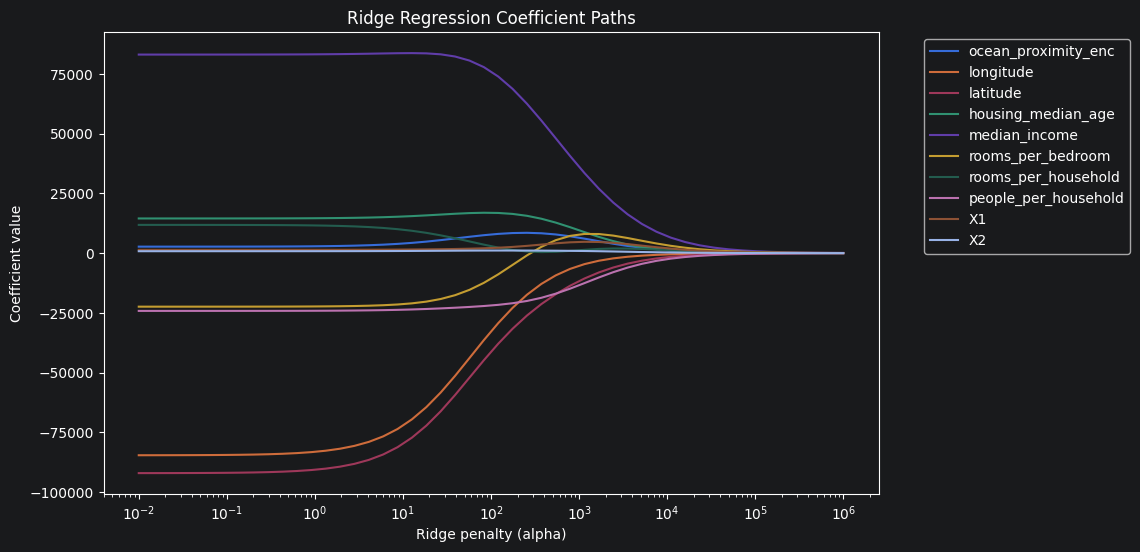

In [233]:
plt.figure(figsize=(10, 6))

plt.plot(ridge_reg_grid, coefs)
plt.xscale("log")
plt.xlabel("Ridge penalty (alpha)")
plt.ylabel("Coefficient value")
plt.title("Ridge Regression Coefficient Paths")
plt.legend(param_names, bbox_to_anchor=(1.05, 1), loc='upper left')
plt.show()


### 5. Fit Lasso regression

Fit the lasso regression (pipeline) on the training data previously created.

In [234]:
lasso_pipe.fit(X_train, y_train)
y_train_hat_lasso = lasso_pipe.predict(X_train)
y_test_hat_lasso = lasso_pipe.predict(X_test)

Compute the root mean square error of the fitted model on both the training and test set. What do you observe?

In [235]:
RMSE_train_lasso = root_mean_squared_error(y_train, y_train_hat_lasso)
RMSE_test_lasso = root_mean_squared_error(y_test, y_test_hat_lasso)
print('Train RMSE:', RMSE_train_lasso)
print('Test RMSE:', RMSE_test_lasso)

Train RMSE: 67636.07112819422
Test RMSE: 69642.05855737998


### 6. Plot Lasso coefficients

As above, we want to plot the coefficients of the lasso regression for different values of the penalty parameter.

Create a (geometrically spaced) grid, named `lasso_grid`, of penalty values ranging from `1` to `1e6`.

In [236]:
lasso_grid = np.geomspace(1, 1e6, num=50)

* Fill in the `??` below.

In [237]:
coefs_lasso = []
for alpha in lasso_grid:
    lasso_pipe.set_params(lasso_reg__alpha = alpha)
    lasso_pipe.fit(X_train, y_train)
    coefs_lasso.append(lasso_pipe.named_steps['lasso_reg'].coef_)

Plot the coefficients computed above.

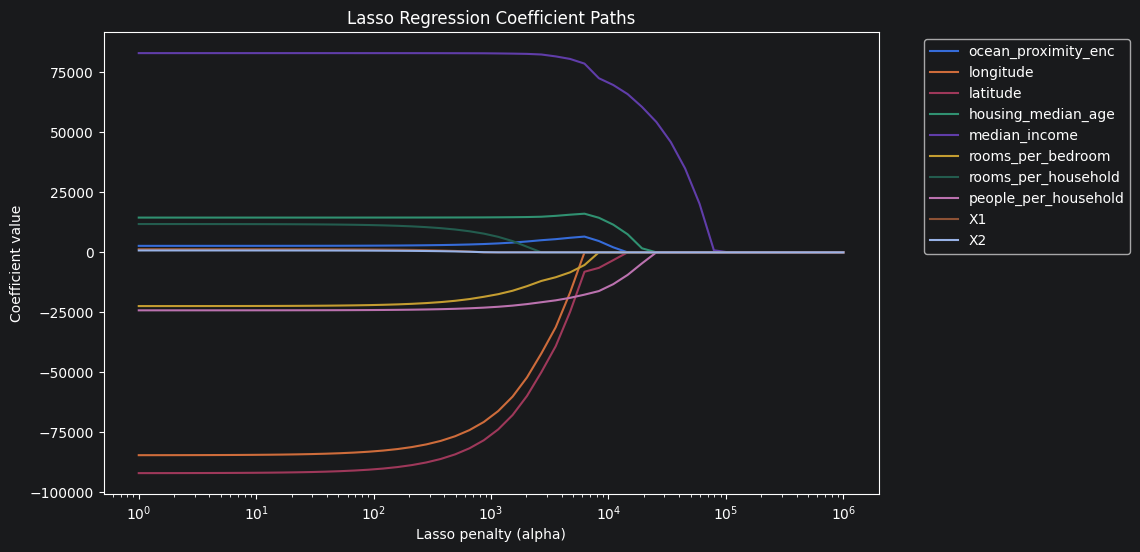

In [238]:
plt.figure(figsize=(10, 6))


plt.plot(lasso_grid, coefs_lasso)
plt.xscale("log")
plt.xlabel("Lasso penalty (alpha)")
plt.ylabel("Coefficient value")
plt.title("Lasso Regression Coefficient Paths")
plt.legend(param_names, bbox_to_anchor=(1.05, 1), loc='upper left')
plt.show()


### 7. Prepare Cross Validation

At this point, we want to find the optimal penalty parameter for our models.
We will use 10-fold cross-validation.

Using the `KFold` class from `sklearn.model_selection` instatiate an object named `folds`.
Set the number of splits equal to 10, the random seed equal to 42, and make sure to shuffle the rows.

In [239]:
from sklearn.model_selection import KFold

folds = KFold(n_splits=10 , shuffle=True, random_state=42)

### 8. CV for Ridge

Create a dictionary with the key-value pair `"ridge_reg__alpha"`, `ridge_reg_grid`. What is the use of this object?

In [240]:
parameters = {"ridge_reg__alpha" : ridge_reg_grid} # don't forget the double __

Import the class `GridSearchCV` from `sklearn.model_selection` and use it to instantiate a **cross-validation object** for the ridge regression. Make sure to include the following parameters: `estimator`, `param_grid`, `scoring`, `cv`.

In [241]:
from sklearn.model_selection import GridSearchCV

ridgeCV = GridSearchCV(estimator = ridge_reg_pipe, param_grid = parameters, scoring = "neg_mean_squared_error",
                       cv = folds)


Run the cross-validation by calling the `fit` method of the **cross-validation object** that you created at the point before.

In [242]:
ridgeCV.fit(X_train, y_train)

GridSearchCV(cv=KFold(n_splits=10, random_state=42, shuffle=True),
             estimator=Pipeline(steps=[('scaler', StandardScaler()),
                                       ('ridge_reg',
                                        Ridge(alpha=np.float64(1000000.0)))]),
             param_grid={'ridge_reg__alpha': array([1.00000000e-02, 1.45634848e-02, 2.12095089e-02, 3.08884360e-02,
       4.49843267e-02, 6.55128557e-02, 9.54095476e-02, 1.38949549e-01,
       2.02358965e-01, 2.947051...
       3.72759372e+02, 5.42867544e+02, 7.90604321e+02, 1.15139540e+03,
       1.67683294e+03, 2.44205309e+03, 3.55648031e+03, 5.17947468e+03,
       7.54312006e+03, 1.09854114e+04, 1.59985872e+04, 2.32995181e+04,
       3.39322177e+04, 4.94171336e+04, 7.19685673e+04, 1.04811313e+05,
       1.52641797e+05, 2.22299648e+05, 3.23745754e+05, 4.71486636e+05,
       6.86648845e+05, 1.00000000e+06])},
             scoring='neg_mean_squared_error')

We want to plot the cross-validation error against different values of the penalty parameter. Fill in the `??`.

In [243]:
# Choose best model that minimizes cv_err
resCV = ridgeCV.cv_results_

mean_scores = -resCV["mean_test_score"]
se_scores = resCV["std_test_score"] / np.sqrt(folds.get_n_splits())
alphas = resCV["param_ridge_reg__alpha"].data

best_index = np.argmin(mean_scores)
min_alpha_ridge = alphas[best_index]
threshold_ridge = mean_scores[best_index] + se_scores[best_index]

candidate = alphas[mean_scores <= threshold_ridge]

one_se_rule_alpha_ridge = np.max(candidate)

print("Minimum alpha:", min_alpha_ridge)
print("1-SD alpha:", one_se_rule_alpha_ridge)
print("Best score for ridge:", np.sqrt(np.min(mean_scores)))

Minimum alpha: 1.9306977288832496
1-SD alpha: 82.86427728546842
Best score for ridge: 68713.18273900451


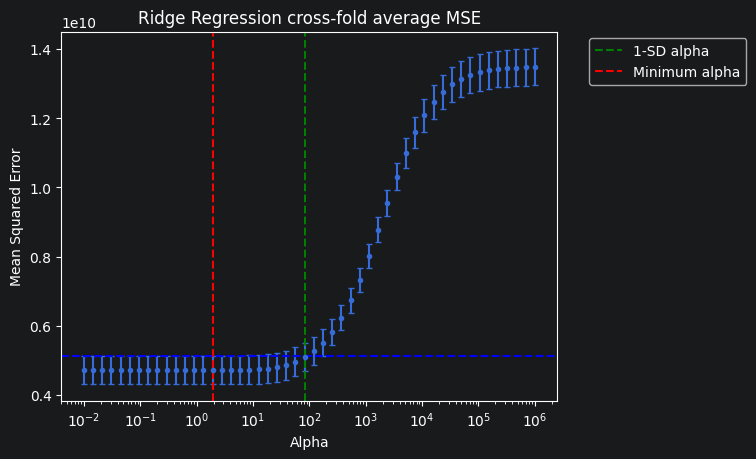

In [244]:
plt.errorbar(x=alphas, y=mean_scores, yerr = se_scores, fmt =".", capsize = 2 )
plt.axvline(x=one_se_rule_alpha_ridge, color = 'g', linestyle = "--", label = '1-SD alpha')
plt.axvline(x=min_alpha_ridge, linestyle = "--", color = "r", label = 'Minimum alpha')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.axhline(y=threshold_ridge, linestyle = "--", color = "b", label = 'Threshold')
plt.xscale('log') # log scale
plt.xlabel("Alpha")
plt.ylabel("Mean Squared Error")
plt.title('Ridge Regression cross-fold average MSE')
plt.show()

### 9. CV for Lasso

Create a dictionary with the key-value pair `"lasso__alpha"`, `lasso_grid`. What is the use of this object?

In [245]:
parameters_lasso = {"lasso_reg__alpha" : lasso_grid}


Create a cross-validation object for the lasso regression. Make sure to specify the following parameters: `estimator`, `param_grid`, `scoring`, `cv`.

In [246]:
lassoCV = GridSearchCV(estimator = lasso_pipe, param_grid = parameters_lasso, scoring = "neg_mean_squared_error",
                       cv = folds)

Run the cross-validation by calling the `fit` method of the **cross-validation object** that you created at the point before.

In [247]:
lassoCV.fit(X_train, y_train)

GridSearchCV(cv=KFold(n_splits=10, random_state=42, shuffle=True),
             estimator=Pipeline(steps=[('scaler', StandardScaler()),
                                       ('lasso_reg',
                                        Lasso(alpha=np.float64(1000000.0)))]),
             param_grid={'lasso_reg__alpha': array([1.00000000e+00, 1.32571137e+00, 1.75751062e+00, 2.32995181e+00,
       3.08884360e+00, 4.09491506e+00, 5.42867544e+00, 7.19685673e+00,
       9.54095476e+00, 1.264855...
       2.68269580e+03, 3.55648031e+03, 4.71486636e+03, 6.25055193e+03,
       8.28642773e+03, 1.09854114e+04, 1.45634848e+04, 1.93069773e+04,
       2.55954792e+04, 3.39322177e+04, 4.49843267e+04, 5.96362332e+04,
       7.90604321e+04, 1.04811313e+05, 1.38949549e+05, 1.84206997e+05,
       2.44205309e+05, 3.23745754e+05, 4.29193426e+05, 5.68986603e+05,
       7.54312006e+05, 1.00000000e+06])},
             scoring='neg_mean_squared_error')

We want to plot the cross-validation error against different values of the penalty parameter. Fill in the `??`.

In [248]:
# Choose best model that minimizes the cv_err
resCV_lasso = lassoCV.cv_results_

mean_scores_lasso = -resCV_lasso["mean_test_score"]
se_scores_lasso = resCV_lasso["std_test_score"] / np.sqrt(folds.get_n_splits())
alphas_lasso = resCV_lasso["param_lasso_reg__alpha"].data

best_index = np.argmin(mean_scores_lasso)
min_alpha_lasso = alphas_lasso[best_index]
threshold_lasso = mean_scores_lasso[best_index] + se_scores[best_index]

candiate_lasso = alphas_lasso[mean_scores_lasso <= threshold_lasso]

one_se_rule_alpha_lasso = np.max(candiate_lasso)

print("Minimum alpha:", min_alpha_lasso)
print("1-SD alpha:", one_se_rule_alpha_lasso)
print("Best score for lasso:", np.sqrt(np.min(mean_scores_lasso)))

Minimum alpha: 281.1768697974231
1-SD alpha: 3556.4803062231285
Best score for lasso: 68694.4015677076


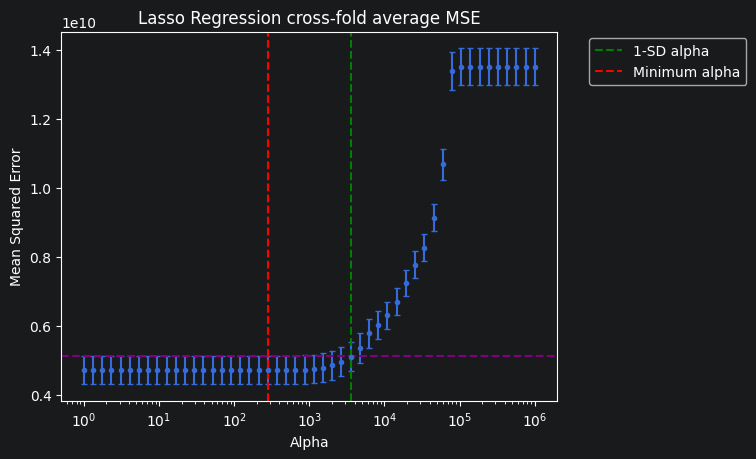

In [249]:
plt.errorbar(x=alphas_lasso, y=mean_scores_lasso, yerr = se_scores_lasso, fmt =".", capsize = 2 )
plt.axvline(x=one_se_rule_alpha_lasso, color = 'g', linestyle = "--", label = '1-SD alpha')
plt.axvline(x=min_alpha_lasso, linestyle = "--", color = "r", label = 'Minimum alpha')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.axhline(y=threshold_lasso, linestyle = "--", color = "purple", label = 'Threshold')
plt.xscale('log') # log scale
plt.xlabel("Alpha")
plt.ylabel("Mean Squared Error")
plt.title('Lasso Regression cross-fold average MSE')
plt.show()

### 10. Compute performance of the two best models

Given the optimal tuning parameter of the ridge and lasso regression, refit both models on the entire training data set.
Furthermore, compute their root mean square error on the test set. How do they compare to the errors obtained before performing the cross-validation?


In [250]:
from sklearn.metrics import mean_squared_error

# Refit best ridge on whole training data and evaluate on test
ridge_best = Ridge(alpha = one_se_rule_alpha_ridge, fit_intercept=True)
ridge_best.fit(X_train, y_train)
rmse_best_ridge_test = root_mean_squared_error(y_test, ridge_best.predict(X_test))
print('Ridge (best) test score:', rmse_best_ridge_test)
print('Ridge test with original alpha:', RMSE_test)



Ridge (best) test score: 69898.07691044587
Ridge test with original alpha: 69641.95294583413


In [251]:
# Refit best lasso on whole training data and evaluate on test
lasso_best = Lasso(alpha = one_se_rule_alpha_lasso, fit_intercept=True)
lasso_best.fit(X_train, y_train)
# Refit best ridge on whole training data and evaluate on test
rmse_best_lasso_test = root_mean_squared_error(y_test, lasso_best.predict(X_test))
print('Lasso (best) test score:', rmse_best_lasso_test)
print('Lasso test with original alpha:', RMSE_test_lasso)

Lasso (best) test score: 70199.85716786815
Lasso test with original alpha: 69642.05855737998


In [252]:
lasso_best.coef_

for i, coef in enumerate(lasso_best.coef_):
    print(param_names[i],":", coef)

ocean_proximity_enc : 2527.083562457066
longitude : -28339.564117142327
latitude : -29832.917598838365
housing_median_age : 1291.8320173716381
median_income : 41808.29187304476
rooms_per_bedroom : -9942.45576331455
rooms_per_household : 1338.788219199006
people_per_household : -23418.906480970985
X1 : 0.0
X2 : 12.947195774337548


## Problem 2

In this problem, you are asked to derive the closed-form solution for the ridge regression coefficients.

Let $\mathbf{X}\in\mathbb{R}^{n\times p}$ denote the matrix of predictors, and let $\mathbf{y}\in\mathbb{R}^n$ denote the target vector.

The optimal ridge regression coefficient vector $\beta^*$, with parameter $\lambda > 0$, is defined as

$$\beta^* := \arg\min_{\beta\in\mathbb{R}^p} \ (\mathbf{y} - \mathbf{X}\beta)^T(\mathbf{y} - \mathbf{X}\beta) + \lambda \beta ^T\beta.$$

Show that 


$$\beta^*  = (\mathbf{X}^T\mathbf{X} + \lambda \mathbf{I}_p)^{-1} \mathbf{X}^T \mathbf{y},$$

where $\mathbf{I}_p$ denote the identity matrix of size $p\times p$.